# ChangeMyView EDA: first pass

**Data:** Cornell ChangeMyView Data v1.0 (Tan, Niculae, Danescu-Niculescu-Mizil & Lee, *Winning Arguments*, WWW 2016).
Download instructions are in the docstring of `cmv_data.py`; files are expected under `data/raw/`.

**Units of analysis**
- **Pair task** (core of our project): an original post (OP) plus two challenger threads replying to it. One thread
  earned a delta (∆) from the OP and one didn't, matched on topic similarity. Our persuasiveness question lives here.
- **OP task**: original posts labeled by whether the OP changed their view at all ("malleability").
- **all/**: every full discussion tree (2.5 GB uncompressed). Stream it with `cd.iter_all_submissions()`; don't load it at once.

**Kernel:** select the project's `.venv` interpreter (VS Code: *Select Kernel → Python Environments → .venv*).

In [1]:
import html
import re

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

import cmv_data as cd

# Chart style: light surface, recessive axes, solid hairline grid.
# Color carries one meaning everywhere: blue = thread WON a delta, orange = did not, gray = plain counts.
WIN, LOSE, NEUTRAL = "#2a78d6", "#eb6834", "#898781"
INK, INK2, MUTED, GRID, AXIS, SURFACE = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7", "#fcfcfb"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": AXIS, "axes.labelcolor": INK2, "axes.titlecolor": INK,
    "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlelocation": "left", "axes.titlepad": 12,
    "axes.labelsize": 11, "xtick.color": AXIS, "ytick.color": AXIS,
    "xtick.labelcolor": INK2, "ytick.labelcolor": INK2,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "grid.linestyle": "-", "axes.axisbelow": True,
    "axes.spines.top": False, "axes.spines.right": False,
    "lines.linewidth": 2, "legend.frameon": False, "legend.labelcolor": INK2,
    "font.family": "sans-serif", "font.size": 11, "figure.dpi": 110,
})
pd.set_option("display.max_colwidth", 100)

In [2]:
pairs, args = cd.load_pairs()   # pairs: one row per pair; args: one row per challenger thread (2 per pair)
ops = cd.load_op_task()         # one row per original post
print(f"pairs {pairs.shape}, args {args.shape}, ops {ops.shape}")
args.head(3)

pairs (4263, 7), args (8526, 11), ops (12272, 7)


,pair_id,split,op_name,is_winner,author,n_comments,text_raw,text,n_words,root_score,created_utc
0,train-0000,train,t3_2ro9ux,1,Account9726,1,"Look at the definition you provided, if we remove the exclusion of things which humans create:\n...","Look at the definition you provided, if we remove the exclusion of things which humans create:\n...",82,20,1.420668e+09
1,train-0000,train,t3_2ro9ux,0,Nepene,1,"You're using natural to mean definition 8\n\n&gt;the universe, with all its phenomena. \n\nhttp:...",You're using natural to mean definition 8\n\n\nhttp://dictionary.reference.com/browse/nature\n\n...,88,1,1.420670e+09
2,train-0001,train,t3_2ro0ti,1,Bradm77,1,[This answer in /r/askscience does a pretty good job of describing essential oils.](http://www.r...,[This answer in /r/askscience does a pretty good job of describing essential oils.](http://www.r...,65,8,1.420677e+09


## 1. Dataset at a glance

In [3]:
order = ["train", "heldout"]
overview = pd.DataFrame({
    "pairs": pairs.groupby("split").size(),
    "unique OPs in pair task": pairs.groupby("split").op_name.nunique(),
    "OP-task posts": ops.groupby("split").size(),
    "OP-task: % OPs who changed view": ops.groupby("split").delta_label.mean().mul(100).round(1),
}).loc[order]
overview

,pairs,unique OPs in pair task,OP-task posts,OP-task: % OPs who changed view
split,,,,
train,3456,2509,10743,29.7
heldout,807,542,1529,44.0


**Read this before modeling**
- The pair task is **50/50 by construction**, so accuracy is the natural metric and 50% is chance.
- Pairs are **not independent**: several pairs share an OP. Use the provided time-based train/heldout split, and
  group by `op_name` for any cross-validation, so the same OP never appears on both sides.
- The OP task's label rate **shifts between periods** (≈30% → ≈44% changed view). A model tuned on train will be
  miscalibrated on heldout.

## 2. What the text cleaning removes
`cd.clean_text` unescapes HTML (the raw text stores `>` as `&gt;`), strips the moderator footnote, drops quoted
lines in challenger replies, and drops EDIT/UPDATE lines in OP text, which often announce who changed the OP's view.

In [4]:
unesc = lambda s: html.unescape(html.unescape(s or ""))
has_line = lambda s, pred: any(pred(l.strip()) for l in unesc(s).splitlines())

no_quote_strip = args.text_raw.map(lambda s: cd.clean_text(s, drop_quotes=False))
words_before = no_quote_strip.map(cd.n_words).sum()
cleaning = pd.Series({
    "OP texts with moderator footnote": pairs.op_text_raw.str.contains("footnote from your moderators", case=False).sum(),
    "  ...remaining after cleaning": pairs.op_text.str.contains("footnote from your moderators", case=False).sum(),
    "OP texts with EDIT/UPDATE lines": pairs.op_text_raw.map(lambda s: has_line(s, cd.EDIT_LINE_RE.match)).sum(),
    "challenger threads that quote ('>') another message": args.text_raw.map(lambda s: has_line(s, lambda l: l.startswith(">"))).sum(),
    "% of challenger words that were quotes": round(100 * (1 - args.n_words.sum() / words_before), 1),
}, name="count").to_frame()
cleaning

,count
OP texts with moderator footnote,2104.0
...remaining after cleaning,0.0
OP texts with EDIT/UPDATE lines,1596.0
challenger threads that quote ('>') another message,2223.0
% of challenger words that were quotes,6.9


## 3. Length is the confound to beat
Winning threads are much longer. Any feature we propose (politeness, ethos/pathos/logos, grammar) has to show
value **beyond length**. Otherwise it may just be measuring length.

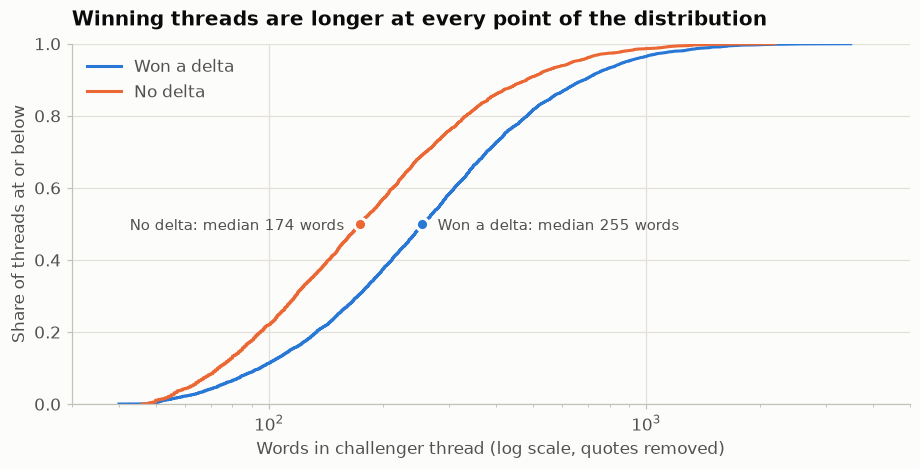

count    25%    50%    75%   mean
split   is_winner                                    
train   0          3456.0  108.0  175.0  299.0  243.0
        1          3456.0  156.0  260.0  428.0  345.0
heldout 0           807.0  102.0  166.0  278.0  223.0
        1           807.0  138.0  241.0  394.0  318.0

In [5]:
fig, ax = plt.subplots(figsize=(8.5, 4.4))
for label, color, name in [(1, WIN, "Won a delta"), (0, LOSE, "No delta")]:
    x = np.sort(args.loc[args.is_winner == label, "n_words"].clip(lower=1).to_numpy())
    y = np.arange(1, len(x) + 1) / len(x)
    ax.plot(x, y, color=color, label=name)
    med = np.median(x)
    ax.plot([med], [0.5], "o", ms=8, color=color, mec=SURFACE, mew=2, zorder=3)
    ax.annotate(f"{name}: median {med:.0f} words", (med, 0.5),
                xytext=(10, -4) if label else (-10, -4), ha="left" if label else "right",
                textcoords="offset points", color=INK2, fontsize=10)
ax.set_xscale("log")
ax.set_xlim(30, 5000)
ax.set_ylim(0, 1)
ax.set_xlabel("Words in challenger thread (log scale, quotes removed)")
ax.set_ylabel("Share of threads at or below")
ax.set_title("Winning threads are longer at every point of the distribution")
ax.legend(loc="upper left")
plt.tight_layout()
plt.show()

args.groupby(["split", "is_winner"]).n_words.describe()[["count", "25%", "50%", "75%", "mean"]].round(0).loc[order]

In [6]:
# Baseline: within each pair, predict that the longer thread won (ties count as half).
wide = args.pivot(index="pair_id", columns="is_winner", values="n_words").rename(columns={1: "winner", 0: "loser"})
wide["split"] = pairs.set_index("pair_id").split
length_baseline = ((wide.winner > wide.loser) + 0.5 * (wide.winner == wide.loser)).groupby(wide.split).mean()
length_baseline.loc[order].map("{:.1%}".format).rename("'longer thread wins' accuracy").to_frame()

,'longer thread wins' accuracy
split,
train,66.9%
heldout,65.6%


## 4. Does a longer exchange help? (research question 2)
Each thread is a rooted path of the challenger's comments (OP replies are not included in the text). More comments
means more back-and-forth with the OP, but also more words, so separate the two before drawing conclusions.

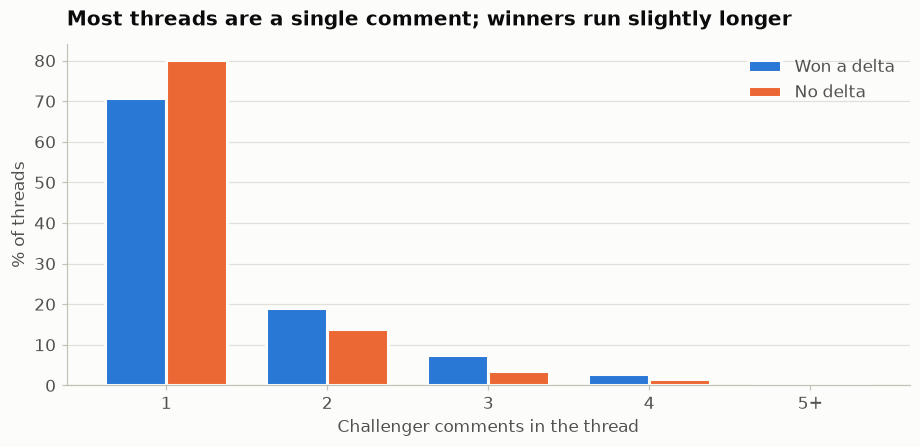

Pairs where the two threads differ in comment count: 39.2%
  ...and the winner has more comments in 62.6% of them


is_winner,Won a delta,No delta
n_comments,,
1,70.7,80.1
2,19.0,14.0
3,7.5,3.5
4,2.7,1.5
5+,0.0,0.9


In [7]:
bins = args.n_comments.clip(upper=5).map(lambda n: "5+" if n == 5 else str(n))
share = (pd.crosstab(bins, args.is_winner, normalize="columns") * 100).rename(columns={1: "Won a delta", 0: "No delta"})
share = share.loc[["1", "2", "3", "4", "5+"], ["Won a delta", "No delta"]]

fig, ax = plt.subplots(figsize=(8.5, 4.2))
xs = np.arange(len(share))
w = 0.38
ax.bar(xs - w / 2, share["Won a delta"], w, color=WIN, edgecolor=SURFACE, linewidth=2, label="Won a delta")
ax.bar(xs + w / 2, share["No delta"], w, color=LOSE, edgecolor=SURFACE, linewidth=2, label="No delta")
ax.set_xticks(xs, share.index)
ax.set_xlabel("Challenger comments in the thread")
ax.set_ylabel("% of threads")
ax.set_title("Most threads are a single comment; winners run slightly longer")
ax.grid(axis="x", visible=False)
ax.legend(loc="upper right")
plt.tight_layout()
plt.show()

wc = args.pivot(index="pair_id", columns="is_winner", values="n_comments")
unequal = wc[1] != wc[0]
print(f"Pairs where the two threads differ in comment count: {unequal.mean():.1%}")
print(f"  ...and the winner has more comments in {(wc[1] > wc[0])[unequal].mean():.1%} of them")
share.round(1)

## 5. Label-leakage checks

In [8]:
leak = pd.DataFrame({
    "threads mentioning delta/∆": args.groupby("is_winner").text.apply(lambda s: s.str.contains(cd.DELTA_RE).sum()),
    "median Reddit score (root comment)": args.groupby("is_winner").root_score.median(),
}).rename(index={1: "Won a delta", 0: "No delta"})
leak

,threads mentioning delta/∆,median Reddit score (root comment)
is_winner,,
No delta,19,2.0
Won a delta,70,6.0


- Delta mentions are rare but lopsided. Pass `strip_delta=True` to `clean_text` before training a text model.
- **Reddit score is measured after the fact** (persuasive replies get upvoted), so treat it as an outcome, never an input.
- OP EDIT lines are already dropped in `pairs.op_text`; keep it that way, because edits often name the winning challenger.

## 6. Topics (setup for research question 1)
The data has no topic labels. A quick NMF over TF-IDF of OP titles and text gives rough topics, so we can check
whether there are enough pairs per topic before asking whether strategies work differently by topic.

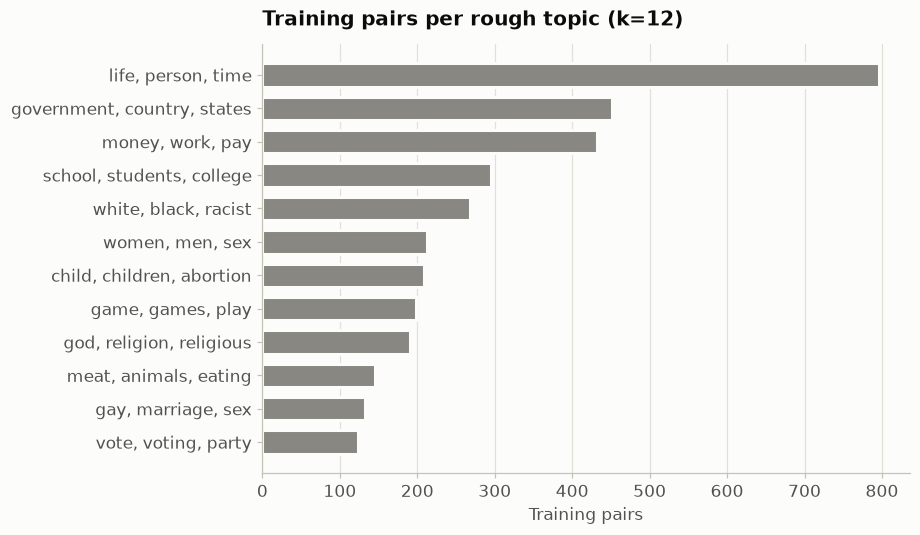

,top words,train pairs,heldout pairs,'longer wins' acc (all)
topic,,,,
0,"life, person, time, feel, good, friends",796,187,0.684
5,"government, country, states, war, power, military",452,130,0.661
7,"money, work, pay, job, tax, company",432,69,0.639
11,"school, students, college, high, education, sports",295,40,0.654
10,"white, black, racist, racism, race, culture",268,89,0.661
1,"women, men, sex, gender, feminism, man",213,52,0.675
4,"child, children, abortion, parents, woman, fetus",209,61,0.676
9,"game, games, play, art, video, sports",198,51,0.659
2,"god, religion, religious, bible, atheist, atheism",190,19,0.713


In [9]:
from sklearn.decomposition import NMF
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS, TfidfVectorizer

K = 12
op_docs = pairs.drop_duplicates("op_name").set_index("op_name")
op_docs = op_docs.assign(doc=op_docs.op_title.str.replace(r"^\s*CMV\s*:?", "", regex=True, flags=re.I) + ". " + op_docs.op_text)
stop = list(ENGLISH_STOP_WORDS | {"cmv", "view", "think", "people", "just", "like", "don", "change", "really",
                                  "know", "way", "make", "want", "say", "does", "thing", "things", "believe",
                                  "doesn", "isn", "ve", "ll", "lot", "point", "argument", "reason", "http", "https",
                                  "www", "com", "reddit", "changemyview", "comments"})
vec = TfidfVectorizer(stop_words=stop, max_df=0.5, min_df=5, token_pattern=r"(?u)\b[a-zA-Z]{3,}\b")
train_ops = op_docs[op_docs.split == "train"]
nmf = NMF(n_components=K, random_state=0, init="nndsvd", max_iter=400).fit(vec.fit_transform(train_ops.doc))

vocab = np.array(vec.get_feature_names_out())
topic_words = [", ".join(vocab[np.argsort(c)[::-1][:6]]) for c in nmf.components_]
op_docs["topic"] = nmf.transform(vec.transform(op_docs.doc)).argmax(axis=1)
pairs["topic"] = pairs.op_name.map(op_docs.topic)

topic_table = pd.DataFrame({
    "top words": topic_words,
    "train pairs": pairs[pairs.split == "train"].topic.value_counts().reindex(range(K), fill_value=0),
    "heldout pairs": pairs[pairs.split == "heldout"].topic.value_counts().reindex(range(K), fill_value=0),
})
wide["topic"] = pairs.set_index("pair_id").topic
topic_table["'longer wins' acc (all)"] = ((wide.winner > wide.loser) + 0.5 * (wide.winner == wide.loser)).groupby(wide.topic).mean().round(3)
topic_table = topic_table.sort_values("train pairs", ascending=False)

fig, ax = plt.subplots(figsize=(8.5, 5))
labels = [", ".join(w.split(", ")[:3]) for w in topic_table["top words"]]
ax.barh(labels[::-1], topic_table["train pairs"][::-1], color=NEUTRAL, edgecolor=SURFACE, linewidth=2, height=0.7)
ax.set_xlabel("Training pairs")
ax.set_title(f"Training pairs per rough topic (k={K})")
ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()
topic_table

Topics are a first draft. The largest one ("life, person, time") is a catch-all, not a real topic. Tune `K`,
read sample titles per topic, and name them by hand before using them in the tool. Small topics will give noisy per-topic conclusions, so report uncertainty (for example, bootstrap CIs).

In [ ]:
# Spot-check the topics with a RANDOM sample of training posts per topic (the most typical posts would flatter the model).
# [share] = how much of the post's topic weight sits in its assigned topic: low means a mixed or unclear post.
N_PER_TOPIC = 8
SEED = 0   # change to draw a fresh sample

topic_weights = nmf.transform(vec.transform(op_docs.doc))
op_docs["weight_share"] = topic_weights.max(axis=1) / topic_weights.sum(axis=1).clip(min=1e-12)
train_posts = op_docs[op_docs.split == "train"]
sample = train_posts.groupby("topic").sample(n=N_PER_TOPIC, random_state=SEED)

for t in topic_table.index:   # largest topic first
    s = sample[sample.topic == t].sort_values("weight_share", ascending=False)
    print(f"\n=== Topic {t}: {topic_words[t]}  ({(train_posts.topic == t).sum()} train posts)")
    for title, w in zip(s.op_title, s.weight_share):
        print(f"  [{w:.0%}] {title[:110]}")

# The same sample as a CSV for hand-checking: fill `correct` with y / n, then compute accuracy per topic.
check_path = cd.DATA_DIR.parent / "interim" / "topic_check_sample.csv"
check_path.parent.mkdir(parents=True, exist_ok=True)
(sample.reset_index()[["topic", "op_name", "op_title", "weight_share"]]
    .assign(topic_words=lambda d: d.topic.map(dict(enumerate(topic_words))), correct="")
    .sort_values(["topic", "weight_share"], ascending=[True, False])
    .to_csv(check_path, index=False))
print(f"\nSaved {len(sample)} rows to {check_path}")

## 7. What this dataset does *not* give us, and next steps
- **No ethos/pathos/logos labels.** We need an annotated argument dataset, or a zero-shot classifier checked
  against a small hand-labeled sample of these threads.
- **No politeness or grammar labels.** Candidates: ConvoKit's politeness strategies transformer; a grammar checker
  such as LanguageTool. Compute these on `args.text` and compare winners against losers **within pairs**,
  controlling for length.
- **Full discussion context** (who replied to whom, OP responses): stream `cd.iter_all_submissions()` and join on `op_name`.
- **Evaluation protocol:** fit on `train`, report on `heldout`, and always show the length baseline next to any model.